In [1]:
from google.colab import files

uploaded = files.upload()

Saving Housing.csv to Housing.csv


In [2]:
import pandas as pd

df = pd.read_csv("Housing.csv")

print(df.head())

      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  


In [3]:
# Display first 5 rows
print("First 5 rows:")
print(df.head())

# Display last 5 rows
print("\nLast 5 rows:")
print(df.tail())

# Check number of rows and columns
print("\nDataset shape:")
print(df.shape)

# Display column names
print("\nColumn names:")
print(df.columns)

# Check data types and information
print("\nDataset information:")
df.info()

First 5 rows:
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  

Last 5 rows:
       price  area  bedrooms  bathrooms  stories mainroad guestroom bas

In [4]:
print(df.describe())

              price          area    bedrooms   bathrooms     stories  \
count  5.450000e+02    545.000000  545.000000  545.000000  545.000000   
mean   4.766729e+06   5150.541284    2.965138    1.286239    1.805505   
std    1.870440e+06   2170.141023    0.738064    0.502470    0.867492   
min    1.750000e+06   1650.000000    1.000000    1.000000    1.000000   
25%    3.430000e+06   3600.000000    2.000000    1.000000    1.000000   
50%    4.340000e+06   4600.000000    3.000000    1.000000    2.000000   
75%    5.740000e+06   6360.000000    3.000000    2.000000    2.000000   
max    1.330000e+07  16200.000000    6.000000    4.000000    4.000000   

          parking  
count  545.000000  
mean     0.693578  
std      0.861586  
min      0.000000  
25%      0.000000  
50%      0.000000  
75%      1.000000  
max      3.000000  


In [5]:
# Count missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Calculate missing value percentages
print("\nMissing value percentage:")
print((df.isnull().sum() / len(df)) * 100)

Missing values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Missing value percentage:
price               0.0
area                0.0
bedrooms            0.0
bathrooms           0.0
stories             0.0
mainroad            0.0
guestroom           0.0
basement            0.0
hotwaterheating     0.0
airconditioning     0.0
parking             0.0
prefarea            0.0
furnishingstatus    0.0
dtype: float64


In [6]:
# Count duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [7]:
# Numerical columns
print("Numerical columns:")
print(df.select_dtypes(include=["int64", "float64"]).columns)

# Categorical columns
print("\nCategorical columns:")
print(df.select_dtypes(include=["object"]).columns)

Numerical columns:
Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking'], dtype='object')

Categorical columns:
Index(['mainroad', 'guestroom', 'basement', 'hotwaterheating',
       'airconditioning', 'prefarea', 'furnishingstatus'],
      dtype='object')


In [8]:
# Make a copy of the original dataset
df = df.copy()

# Count rows before cleaning
print("Rows before cleaning:", df.shape[0])

# Remove duplicate rows
df = df.drop_duplicates()

# Remove rows with missing area or price
df = df.dropna(subset=["area", "price"])

# Remove zero or negative area and price
df = df[(df["area"] > 0) & (df["price"] > 0)]

# Count rows after cleaning
print("Rows after cleaning:", df.shape[0])

# Check missing values again
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Rows before cleaning: 545
Rows after cleaning: 545

Missing values after cleaning:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [9]:
# Independent variable (Input)
X = df[["area"]]

# Dependent variable (Output)
y = df["price"]

print("Input variable (X):")
print(X.head())

print("\nOutput variable (y):")
print(y.head())

Input variable (X):
   area
0  7420
1  8960
2  9960
3  7500
4  7420

Output variable (y):
0    13300000
1    12250000
2    12250000
3    12215000
4    11410000
Name: price, dtype: int64


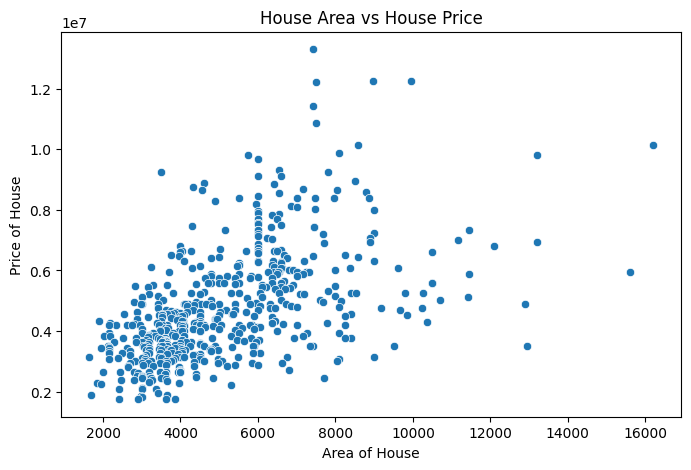

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.scatterplot(x="area", y="price", data=df)

plt.title("House Area vs House Price")
plt.xlabel("Area of House")
plt.ylabel("Price of House")

plt.show()

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training input:", X_train.shape)
print("Testing input:", X_test.shape)

print("Training output:", y_train.shape)
print("Testing output:", y_test.shape)

Training input: (436, 1)
Testing input: (109, 1)
Training output: (436,)
Testing output: (109,)


In [12]:
from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [13]:
# Calculate intercept (b0)
b0 = model.intercept_

# Calculate coefficient (b1)
b1 = model.coef_[0]

print("Intercept (b0):", b0)
print("Coefficient (b1):", b1)

print("\nLinear Regression Equation:")
print(f"Price = {b0:.2f} + ({b1:.2f} × Area)")

Intercept (b0): 2512254.2639593435
Coefficient (b1): 425.72984193878284

Linear Regression Equation:
Price = 2512254.26 + (425.73 × Area)


In [14]:
# Predict house prices using testing data
y_pred = model.predict(X_test)

print("Predicted House Prices:")
print(y_pred)

Predicted House Prices:
[5024060.33139816 5279498.23656143 4232202.82539203 4640903.47365326
 4198144.43803692 5373158.80178796 6139472.51727777 4636646.17523387
 3891618.951841   3661724.83719406 6165016.3077941  4187075.46214652
 4095969.27597162 3832016.77396957 4202401.73645631 4057653.59019713
 3363713.94783691 5066633.31559204 5002773.83930122 5066633.31559204
 4649418.07049203 5417860.43519154 4065742.45719396 4130027.66332672
 6024525.4599543  6752523.48966962 3827759.47555018 3789443.78977569
 8131888.17755128 3789443.78977569 4215173.63171447 3840531.37080835
 5066633.31559204 5328457.16838439 4545114.25921703 4470611.53687774
 4490195.10960693 3866075.16132467 3993794.11390631 3698763.33344273
 5909578.40263083 4057653.59019713 5245439.84920633 4300319.60010223
 5385930.69704613 5017674.38376908 5066633.31559204 4487640.7305553
 5939379.49156655 3789443.78977569 5694584.83245175 3789443.78977569
 5820175.13582369 4428038.55268387 4061910.88861651 3751128.1040012
 4960200.855

In [15]:
# Create a comparison DataFrame
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print(comparison.head(10))

   Actual Price  Predicted Price
0       4060000     5.024060e+06
1       6650000     5.279498e+06
2       3710000     4.232203e+06
3       6440000     4.640903e+06
4       2800000     4.198144e+06
5       4900000     5.373159e+06
6       5250000     6.139473e+06
7       4543000     4.636646e+06
8       2450000     3.891619e+06
9       3353000     3.661725e+06


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)

Mean Absolute Error (MAE): 1474748.1337969352
Mean Squared Error (MSE): 3675286604768.185
Root Mean Squared Error (RMSE): 1917103.7021424233
R2 Score: 0.27287851871974644


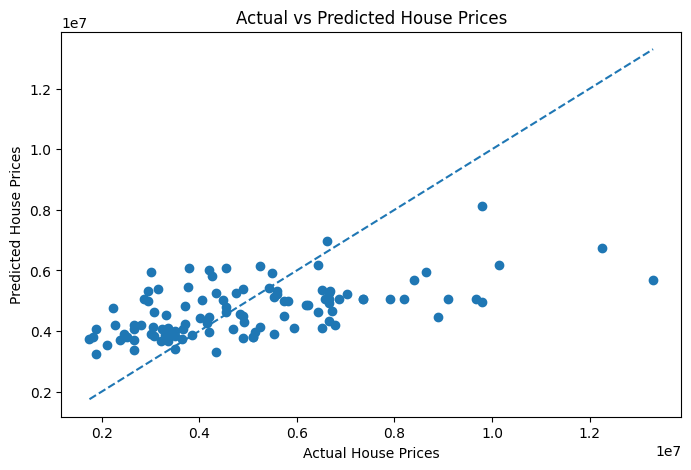

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.show()

In [18]:
# Select a new house area within the training data range
new_area = (X_train["area"].min() + X_train["area"].max()) / 2

# Create new house data
new_house = pd.DataFrame({
    "area": [new_area]
})

# Predict the house price
new_prediction = model.predict(new_house)

print("New House Area:", new_area)
print("Predicted House Price:", new_prediction[0])

New House Area: 8925.0
Predicted House Price: 6311893.1032629805


In [19]:
comparison.to_csv("Activity2_Prediction_Results.csv", index=False)

print("Prediction results saved successfully!")

Prediction results saved successfully!


In [20]:
from google.colab import files

files.download("Activity2_Prediction_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>